In [18]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Land-Cover Dataset Verification

This section checks the downloaded Sentinel-2 image dataset saved in Google Drive. It verifies that each PNG can be opened and has the expected dimensions (64×64) and RGB mode.

**Before running:** In Google Colab, run the Drive-mount cell first, then run the verification cell. This notebook only reads/checks files; it does not download, delete, or modify images.

In [17]:
import os
import pandas as pd
from PIL import Image

DATASET_DIR = "/content/drive/MyDrive/landcover_project/landcover_dataset"

splits = ["train", "val", "test"]
classes = [
    "Tree_Cover",
    "Cropland",
    "Built_Up",
    "Bare_Sparse_Vegetation",
    "Permanent_Water"
]

# Check that the dataset folder is available before scanning.
if not os.path.isdir(DATASET_DIR):
    raise FileNotFoundError(f"Dataset folder not found: {DATASET_DIR}\nCheck that Google Drive is mounted and the path is correct.")

results = []
missing_folders = []

for split in splits:
    for class_name in classes:
        folder = os.path.join(DATASET_DIR, split, class_name)
        if not os.path.isdir(folder):
            missing_folders.append(folder)
            results.append({
                "Split": split,
                "Class": class_name,
                "Valid images": 0,
                "Invalid images": 0,
                "Folder status": "MISSING"
            })
            continue

        valid = 0
        invalid = 0

        for filename in os.listdir(folder):
            if not filename.lower().endswith('.png'):
                continue

            path = os.path.join(folder, filename)
            try:
                with Image.open(path) as img:
                    img.verify()
                with Image.open(path) as img:
                    if img.size == (64, 64) and img.mode == 'RGB':
                        valid += 1
                    else:
                        invalid += 1
            except Exception:
                invalid += 1

        results.append({
            "Split": split,
            "Class": class_name,
            "Valid images": valid,
            "Invalid images": invalid,
            "Folder status": "OK"
        })

results_df = pd.DataFrame(results)
display(results_df)

print("\nTotal valid images:", results_df["Valid images"].sum())
print("Total invalid images:", results_df["Invalid images"].sum())
print("\nImages per split:")
print(results_df.groupby("Split")["Valid images"].sum())

if missing_folders:
    print("\nWARNING: These folders are missing:")
    for folder in missing_folders:
        print(folder)

,Split,Class,Valid images,Invalid images,Folder status
0,train,Tree_Cover,360,0,OK
1,train,Cropland,359,0,OK
2,train,Built_Up,362,0,OK
3,train,Bare_Sparse_Vegetation,342,0,OK
4,train,Permanent_Water,343,0,OK
5,val,Tree_Cover,69,0,OK
6,val,Cropland,71,0,OK
7,val,Built_Up,70,0,OK
8,val,Bare_Sparse_Vegetation,80,0,OK
9,val,Permanent_Water,77,0,OK



Total valid images: 2500
Total invalid images: 0

Images per split:
Split
test      367
train    1766
val       367
Name: Valid images, dtype: int64


#Visualize a random sample
### This cell displays random images from the dataset with their class and split. Use it to check for blank images, heavy cloud cover, unusual colors, or obvious label mismatches. It only reads images and does not modify them.

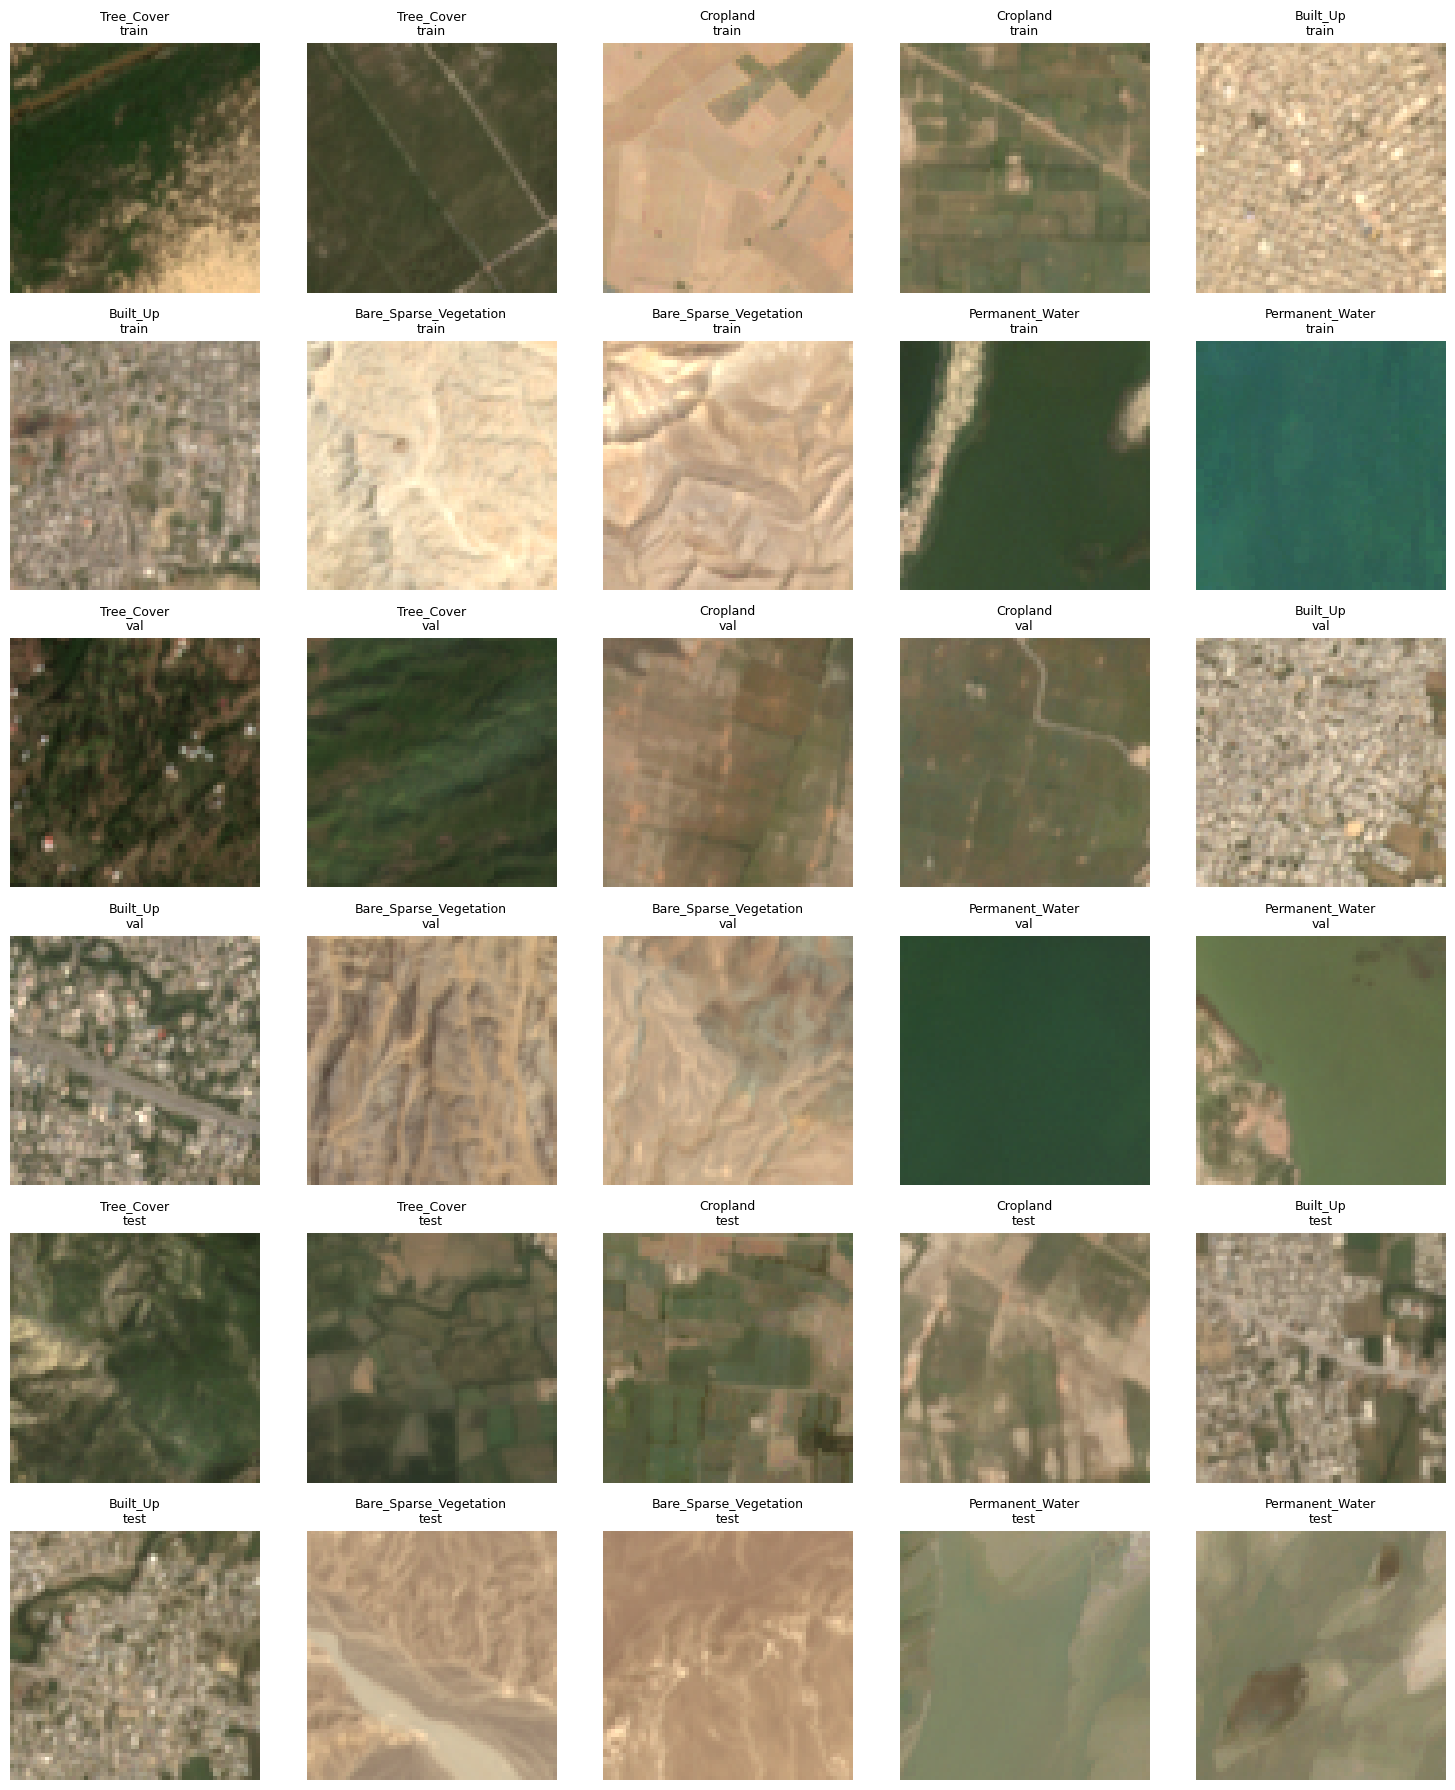

In [19]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

DATASET_DIR = "/content/drive/MyDrive/landcover_project/landcover_dataset"
random.seed(42)

# Choose how many images to display from each split.
SAMPLES_PER_CLASS = 2  # 2 per class per split = up to 30 images

splits = ["train", "val", "test"]
classes = [
    "Tree_Cover",
    "Cropland",
    "Built_Up",
    "Bare_Sparse_Vegetation",
    "Permanent_Water"
]

samples = []
for split in splits:
    for class_name in classes:
        folder = os.path.join(DATASET_DIR, split, class_name)
        files = [
            os.path.join(folder, f)
            for f in os.listdir(folder)
            if f.lower().endswith(".png")
        ]
        chosen = random.sample(files, min(SAMPLES_PER_CLASS, len(files)))
        for path in chosen:
            samples.append((path, split, class_name))

# Display a grid of the selected images.
ncols = 5
nrows = (len(samples) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3 * nrows))
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for ax, (path, split, class_name) in zip(axes, samples):
    with Image.open(path) as img:
        ax.imshow(img)
    ax.set_title(f"{class_name}\n{split}", fontsize=9)
    ax.axis("off")

for ax in axes[len(samples):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

#Optional: inspect more images
###If the first grid looks reasonable, change SAMPLES_PER_CLASS = 2 to 4 and rerun the visualization cell. That displays up to 60 images. You can also change random.seed(42) to another integer to sample different images.

In [20]:
import torch
import torchvision
import sklearn
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Scikit-learn:", sklearn.__version__)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Training will use CPU.")

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Scikit-learn: 1.6.1
GPU: Tesla T4


In [21]:
import os
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Dataset location in Google Drive
DATASET_DIR = "/content/drive/MyDrive/landcover_project/landcover_dataset"

# ImageNet normalization, suitable for our pretrained ResNet18 experiment
normalize = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

# Training: resize and apply light data augmentation
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    normalize
])

# Validation and testing: no random augmentation
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    normalize
])

# Load each split
train_dataset = datasets.ImageFolder(
    os.path.join(DATASET_DIR, "train"),
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    os.path.join(DATASET_DIR, "val"),
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    os.path.join(DATASET_DIR, "test"),
    transform=eval_transform
)

# Ensure all splits use the same class-to-index mapping
assert train_dataset.class_to_idx == val_dataset.class_to_idx
assert train_dataset.class_to_idx == test_dataset.class_to_idx

print("Classes:", train_dataset.classes)
print("Class mapping:", train_dataset.class_to_idx)
print()
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))
print("Total images:", len(train_dataset) + len(val_dataset) + len(test_dataset))

Classes: ['Bare_Sparse_Vegetation', 'Built_Up', 'Cropland', 'Permanent_Water', 'Tree_Cover']
Class mapping: {'Bare_Sparse_Vegetation': 0, 'Built_Up': 1, 'Cropland': 2, 'Permanent_Water': 3, 'Tree_Cover': 4}

Training images: 1766
Validation images: 367
Test images: 367
Total images: 2500


In [22]:
import torch
from torch.utils.data import DataLoader

# Use the GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

BATCH_SIZE = 32

# Reproducibility
SEED = 42
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# Inspect one batch
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))
print("Number of test batches:", len(test_loader))

Training device: cuda
Batch image shape: torch.Size([32, 3, 224, 224])
Batch label shape: torch.Size([32])
Number of training batches: 56
Number of validation batches: 12
Number of test batches: 12


In [23]:
import torch.nn as nn
from torchvision import models

NUM_CLASSES = len(train_dataset.classes)

# Create ResNet18 with randomly initialized weights
model = models.resnet18(weights=None)

# Replace the final classification layer for our 5 classes
model.fc = nn.Linear(
    model.fc.in_features,
    NUM_CLASSES
)

# Move the model to the GPU
model = model.to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Model: ResNet18 (trained from scratch)")
print("Pretrained weights: None")
print("Number of classes:", NUM_CLASSES)
print("Class names:", train_dataset.classes)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print("Model device:", next(model.parameters()).device)

Model: ResNet18 (trained from scratch)
Pretrained weights: None
Number of classes: 5
Class names: ['Bare_Sparse_Vegetation', 'Built_Up', 'Cropland', 'Permanent_Water', 'Tree_Cover']
Total parameters: 11,179,077
Trainable parameters: 11,179,077
Model device: cuda:0


In [24]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 15

print("Loss function:", criterion)
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Epochs:", EPOCHS)

Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001
Epochs: 15


In [25]:
import copy
import time

best_val_accuracy = 0.0
best_model_state = copy.deepcopy(model.state_dict())

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(EPOCHS):
    start_time = time.time()

    # --------------------
    # Training
    # --------------------
    model.train()

    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss = running_loss / train_total
    train_accuracy = train_correct / train_total

    # --------------------
    # Validation
    # --------------------
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_accuracy = val_correct / val_total

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    # Save the best model based on validation accuracy
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_model_state = copy.deepcopy(model.state_dict())

    elapsed = time.time() - start_time

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Time: {elapsed:.1f}s"
    )

# Restore the best-performing validation checkpoint
model.load_state_dict(best_model_state)

print(f"\nBest validation accuracy: {best_val_accuracy:.4f}")

Epoch [01/15] Train Loss: 0.7099 | Train Acc: 0.7661 | Val Loss: 1.4133 | Val Acc: 0.5395 | Time: 9.2s
Epoch [02/15] Train Loss: 0.5587 | Train Acc: 0.8165 | Val Loss: 2.1561 | Val Acc: 0.5940 | Time: 8.9s
Epoch [03/15] Train Loss: 0.5604 | Train Acc: 0.8041 | Val Loss: 0.6079 | Val Acc: 0.8338 | Time: 8.8s
Epoch [04/15] Train Loss: 0.5038 | Train Acc: 0.8194 | Val Loss: 0.6703 | Val Acc: 0.7411 | Time: 8.7s
Epoch [05/15] Train Loss: 0.4888 | Train Acc: 0.8369 | Val Loss: 0.4459 | Val Acc: 0.8420 | Time: 9.7s
Epoch [06/15] Train Loss: 0.4048 | Train Acc: 0.8573 | Val Loss: 0.5361 | Val Acc: 0.7629 | Time: 8.6s
Epoch [07/15] Train Loss: 0.4327 | Train Acc: 0.8573 | Val Loss: 0.4978 | Val Acc: 0.7956 | Time: 8.6s
Epoch [08/15] Train Loss: 0.4239 | Train Acc: 0.8545 | Val Loss: 0.3556 | Val Acc: 0.8747 | Time: 8.8s
Epoch [09/15] Train Loss: 0.4401 | Train Acc: 0.8431 | Val Loss: 0.2704 | Val Acc: 0.9210 | Time: 8.6s
Epoch [10/15] Train Loss: 0.3903 | Train Acc: 0.8641 | Val Loss: 0.5682 |

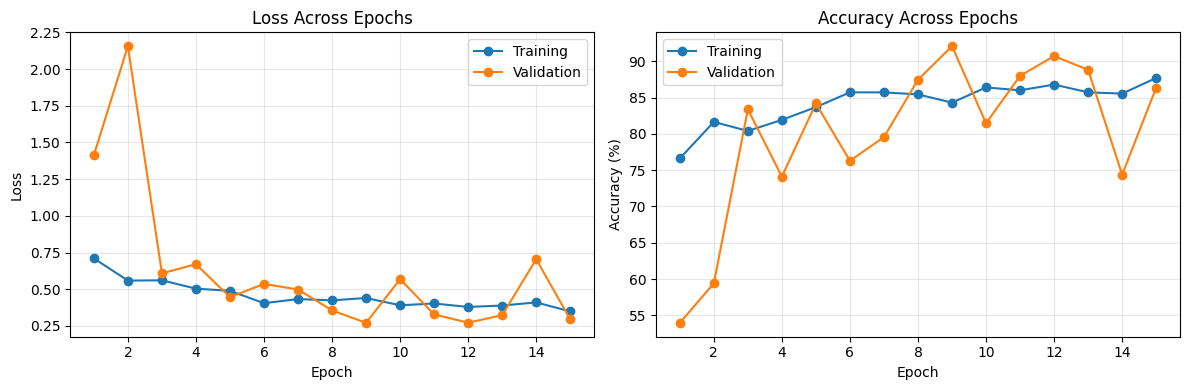

In [26]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_loss"], marker="o", label="Training")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation")
plt.title("Loss Across Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(
    epochs,
    [x * 100 for x in history["train_accuracy"]],
    marker="o",
    label="Training"
)
plt.plot(
    epochs,
    [x * 100 for x in history["val_accuracy"]],
    marker="o",
    label="Validation"
)
plt.title("Accuracy Across Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [27]:
best_epoch = max(
    range(len(history["val_accuracy"])),
    key=lambda i: history["val_accuracy"][i]
) + 1

print("Best epoch:", best_epoch)
print(f"Best validation accuracy: {best_val_accuracy * 100:.2f}%")

# Save the best checkpoint to Google Drive
checkpoint_path = (
    "/content/drive/MyDrive/landcover_project/"
    "resnet18_scratch_best.pth"
)

torch.save(
    {
        "model_state_dict": best_model_state,
        "class_to_idx": train_dataset.class_to_idx,
        "best_epoch": best_epoch,
        "best_val_accuracy": best_val_accuracy,
    },
    checkpoint_path
)

print("Checkpoint saved to:", checkpoint_path)

Best epoch: 9
Best validation accuracy: 92.10%
Checkpoint saved to: /content/drive/MyDrive/landcover_project/resnet18_scratch_best.pth


Validation Accuracy: 92.10%

Classification Report:

                        precision    recall  f1-score   support

Bare_Sparse_Vegetation     0.9315    0.8500    0.8889        80
              Built_Up     0.8750    1.0000    0.9333        70
              Cropland     0.8553    0.9155    0.8844        71
       Permanent_Water     0.9718    0.8961    0.9324        77
            Tree_Cover     0.9851    0.9565    0.9706        69

              accuracy                         0.9210       367
             macro avg     0.9237    0.9236    0.9219       367
          weighted avg     0.9245    0.9210    0.9210       367



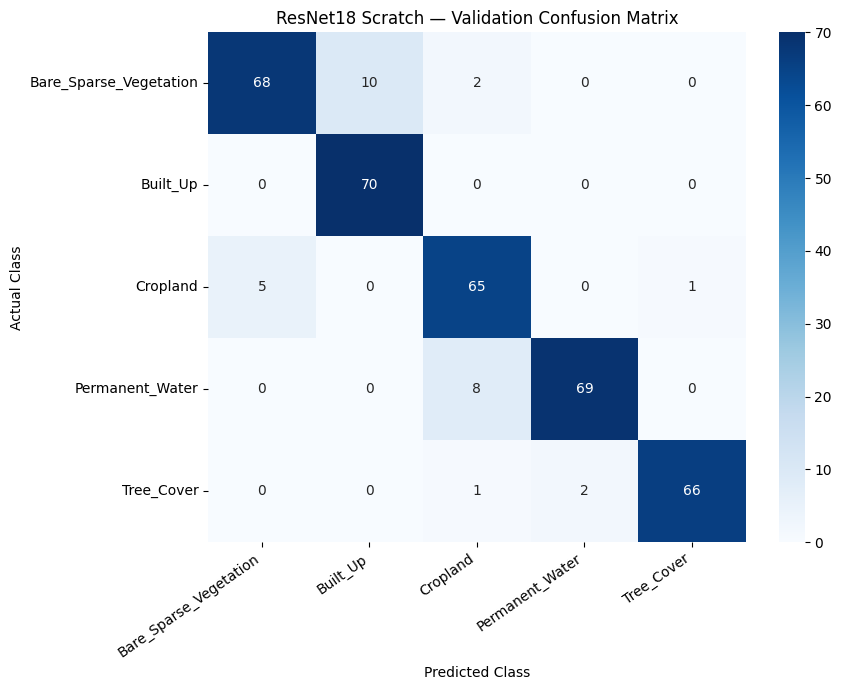

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Use the best checkpoint already restored in `model`
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

# Calculate overall accuracy
accuracy = accuracy_score(all_labels, all_predictions)
print(f"Validation Accuracy: {accuracy * 100:.2f}%")

# Per-class precision, recall, and F1-score
class_names = train_dataset.classes

print("\nClassification Report:\n")
print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("ResNet18 Scratch — Validation Confusion Matrix")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [29]:
import json
import os

PROJECT_DIR = "/content/drive/MyDrive/landcover_project"
os.makedirs(PROJECT_DIR, exist_ok=True)

# Save training history
with open(
    os.path.join(PROJECT_DIR, "scratch_training_history.json"),
    "w"
) as f:
    json.dump(history, f, indent=4)

# Save experiment summary
scratch_summary = {
    "model": "ResNet18",
    "initialization": "random",
    "epochs": EPOCHS,
    "best_epoch": best_epoch,
    "best_validation_accuracy": best_val_accuracy,
    "train_images": len(train_dataset),
    "validation_images": len(val_dataset),
    "test_images": len(test_dataset),
    "classes": train_dataset.classes
}

with open(
    os.path.join(PROJECT_DIR, "scratch_model_summary.json"),
    "w"
) as f:
    json.dump(scratch_summary, f, indent=4)

print("Scratch-model experiment records saved.")

Scratch-model experiment records saved.


In [30]:
import copy
import torch
import torch.nn as nn
import torch.optim as optim
import time

# Restore the best weights from the original 15 epochs
model.load_state_dict(best_model_state)

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.0003,
    weight_decay=0.0001
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

FINE_TUNE_EPOCHS = 20
PATIENCE = 5

# Track the best result across both training phases
best_ft_accuracy = best_val_accuracy
best_ft_loss = float("inf")
best_ft_state = copy.deepcopy(model.state_dict())
epochs_without_improvement = 0

fine_tune_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(FINE_TUNE_EPOCHS):
    start_time = time.time()

    # Training
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    # Validation
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total

    scheduler.step(val_loss)

    fine_tune_history["train_loss"].append(train_loss)
    fine_tune_history["train_accuracy"].append(train_accuracy)
    fine_tune_history["val_loss"].append(val_loss)
    fine_tune_history["val_accuracy"].append(val_accuracy)

    # Keep the best checkpoint; use lower validation loss to break ties
    improved = (
        val_accuracy > best_ft_accuracy
        or (
            val_accuracy == best_ft_accuracy
            and val_loss < best_ft_loss
        )
    )

    if improved:
        best_ft_accuracy = val_accuracy
        best_ft_loss = val_loss
        best_ft_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    elapsed = time.time() - start_time
    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Fine-tune [{epoch + 1:02d}/{FINE_TUNE_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"LR: {current_lr:.6f} | "
        f"Time: {elapsed:.1f}s"
    )

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping: validation accuracy did not improve.")
        break

# Restore the best checkpoint from fine-tuning
model.load_state_dict(best_ft_state)

# Update the best checkpoint variables for subsequent cells
best_model_state = copy.deepcopy(best_ft_state)
best_val_accuracy = best_ft_accuracy

print(f"\nBest validation accuracy: {best_ft_accuracy * 100:.2f}%")

Fine-tune [01/20] Train Loss: 0.3509 | Train Acc: 0.8783 | Val Loss: 0.3637 | Val Acc: 0.8174 | LR: 0.000300 | Time: 9.1s
Fine-tune [02/20] Train Loss: 0.3429 | Train Acc: 0.8766 | Val Loss: 0.2734 | Val Acc: 0.9101 | LR: 0.000300 | Time: 10.7s
Fine-tune [03/20] Train Loss: 0.3413 | Train Acc: 0.8732 | Val Loss: 0.3647 | Val Acc: 0.8665 | LR: 0.000300 | Time: 9.2s
Fine-tune [04/20] Train Loss: 0.3242 | Train Acc: 0.8913 | Val Loss: 0.3893 | Val Acc: 0.8501 | LR: 0.000300 | Time: 9.4s
Fine-tune [05/20] Train Loss: 0.2894 | Train Acc: 0.8975 | Val Loss: 0.2578 | Val Acc: 0.9155 | LR: 0.000300 | Time: 9.1s
Early stopping: validation accuracy did not improve.

Best validation accuracy: 92.10%


##the validation accuracy is good but more can be achived with a better 128 x 128 dataset. So another experiment will be run with a higher image resoultion

In [2]:
from google.colab import drive
drive.mount("/content/drive")

import os
from PIL import Image
from collections import Counter

DATA_DIR = "/content/drive/MyDrive/landcover_project/landcover_dataset_128"

splits = ["train", "val", "test"]

for split in splits:
    split_dir = os.path.join(DATA_DIR, split)
    print(f"\n{split.upper()}")

    total = 0
    for cls in sorted(os.listdir(split_dir)):
        class_dir = os.path.join(split_dir, cls)

        if not os.path.isdir(class_dir):
            continue

        images = [
            f for f in os.listdir(class_dir)
            if f.lower().endswith((".png", ".jpg", ".jpeg"))
        ]

        total += len(images)

        if images:
            img = Image.open(os.path.join(class_dir, images[0]))
            print(f"{cls}: {len(images)} images | sample size: {img.size}")

    print("Total:", total)

Mounted at /content/drive

TRAIN
Bare_Sparse_Vegetation: 338 images | sample size: (128, 128)
Built_Up: 356 images | sample size: (128, 128)
Cropland: 347 images | sample size: (128, 128)
Permanent_Water: 345 images | sample size: (128, 128)
Tree_Cover: 363 images | sample size: (128, 128)
Total: 1749

VAL
Bare_Sparse_Vegetation: 81 images | sample size: (128, 128)
Built_Up: 71 images | sample size: (128, 128)
Cropland: 78 images | sample size: (128, 128)
Permanent_Water: 78 images | sample size: (128, 128)
Tree_Cover: 67 images | sample size: (128, 128)
Total: 375

TEST
Bare_Sparse_Vegetation: 81 images | sample size: (128, 128)
Built_Up: 73 images | sample size: (128, 128)
Cropland: 75 images | sample size: (128, 128)
Permanent_Water: 77 images | sample size: (128, 128)
Tree_Cover: 70 images | sample size: (128, 128)
Total: 376


In [3]:
import os
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

DATA_DIR = "/content/drive/MyDrive/landcover_project/landcover_dataset_128"

BATCH_SIZE = 32
NUM_WORKERS = 2

train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.ImageFolder(
    os.path.join(DATA_DIR, "train"),
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    os.path.join(DATA_DIR, "val"),
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    os.path.join(DATA_DIR, "test"),
    transform=eval_transform
)

assert train_dataset.class_to_idx == val_dataset.class_to_idx
assert train_dataset.class_to_idx == test_dataset.class_to_idx

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=NUM_WORKERS, pin_memory=True
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=NUM_WORKERS, pin_memory=True
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=NUM_WORKERS, pin_memory=True
)

print("Classes:", train_dataset.class_to_idx)
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
# print("Test:", len(test_dataset))

Classes: {'Bare_Sparse_Vegetation': 0, 'Built_Up': 1, 'Cropland': 2, 'Permanent_Water': 3, 'Tree_Cover': 4}
Train: 1749
Validation: 375


In [4]:
import torch

print("Class mapping:", train_dataset.class_to_idx)

images, labels = next(iter(train_loader))

print("Batch shape:", images.shape)
print("Label shape:", labels.shape)
print("Image tensor dtype:", images.dtype)
print("Label range:", labels.min().item(), "to", labels.max().item())

assert images.shape[1:] == (3, 128, 128)
assert len(train_dataset.classes) == 5

print("Dataset checks passed!")

Class mapping: {'Bare_Sparse_Vegetation': 0, 'Built_Up': 1, 'Cropland': 2, 'Permanent_Water': 3, 'Tree_Cover': 4}
Batch shape: torch.Size([32, 3, 128, 128])
Label shape: torch.Size([32])
Image tensor dtype: torch.float32
Label range: 0 to 4
Dataset checks passed!


In [5]:
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 5)
model = model.to(device)

print("Device:", device)
print("Input resolution: 128x128")

Device: cuda
Input resolution: 128x128


In [6]:
import os

PROJECT_DIR = "/content/drive/MyDrive/landcover_project"

paths_to_check = [
    os.path.join(PROJECT_DIR, "landcover_split_metadata.csv"),
    os.path.join(PROJECT_DIR, "landcover_split_metadata_128.csv"),
    os.path.join(PROJECT_DIR, "selected_candidates.csv"),
    os.path.join(PROJECT_DIR, "landcover_dataset"),
    os.path.join(PROJECT_DIR, "landcover_dataset_128"),
]

for path in paths_to_check:
    print(("FOUND  " if os.path.exists(path) else "MISSING"), path)

FOUND   /content/drive/MyDrive/landcover_project/landcover_split_metadata.csv
FOUND   /content/drive/MyDrive/landcover_project/landcover_split_metadata_128.csv
FOUND   /content/drive/MyDrive/landcover_project/selected_candidates.csv
FOUND   /content/drive/MyDrive/landcover_project/landcover_dataset
FOUND   /content/drive/MyDrive/landcover_project/landcover_dataset_128


In [7]:
import pandas as pd
import os

PROJECT_DIR = "/content/drive/MyDrive/landcover_project"

meta64_path = os.path.join(
    PROJECT_DIR, "landcover_split_metadata.csv"
)
meta128_path = os.path.join(
    PROJECT_DIR, "landcover_split_metadata_128.csv"
)

meta64 = pd.read_csv(meta64_path)
meta128 = pd.read_csv(meta128_path)

print("64x64 metadata shape:", meta64.shape)
print("128x128 metadata shape:", meta128.shape)

print("\n64x64 columns:")
print(meta64.columns.tolist())

print("\n128x128 columns:")
print(meta128.columns.tolist())

print("\n64x64 preview:")
display(meta64.head(3))

print("\n128x128 preview:")
display(meta128.head(3))

64x64 metadata shape: (2500, 11)
128x128 metadata shape: (2500, 10)

64x64 columns:
['class_id', 'Class', 'Latitude', 'Longitude', 'Purity (%)', 'sampling_region', 'x_km', 'y_km', 'geo_group', 'split', 'image_id']

128x128 columns:
['class_id', 'Class', 'Latitude', 'Longitude', 'Purity (%)', 'sampling_region', 'x_km', 'y_km', 'geo_group', 'split']

64x64 preview:


,class_id,Class,Latitude,Longitude,Purity (%),sampling_region,x_km,y_km,geo_group,split,image_id
0,60,Bare_Sparse_Vegetation,26.213624,69.728505,100.0,Sindh,6742.143428,2918.100575,35,train,img_00000
1,60,Bare_Sparse_Vegetation,28.531277,63.023480,100.0,NaN,6093.825467,3176.101755,2,train,img_00001
2,60,Bare_Sparse_Vegetation,25.735720,66.096616,100.0,Sindh,6390.971199,2864.900331,7,train,img_00002



128x128 preview:


,class_id,Class,Latitude,Longitude,Purity (%),sampling_region,x_km,y_km,geo_group,split
0,60,Bare_Sparse_Vegetation,26.213624,69.728505,100.0,Sindh,6742.143428,2918.100575,35,train
1,60,Bare_Sparse_Vegetation,28.531277,63.023480,100.0,NaN,6093.825467,3176.101755,2,train
2,60,Bare_Sparse_Vegetation,25.735720,66.096616,100.0,Sindh,6390.971199,2864.900331,7,train


In [8]:
import pandas as pd
import numpy as np

# 1. Compare split counts
print("64x64 split counts:")
print(pd.crosstab(meta64["split"], meta64["Class"]))

print("\n128x128 split counts:")
print(pd.crosstab(meta128["split"], meta128["Class"]))

# 2. Check whether class, coordinates, and geographic groups match
compare_cols = [
    "class_id", "Class", "Latitude", "Longitude", "geo_group"
]

a = meta64[compare_cols].copy().reset_index(drop=True)
b = meta128[compare_cols].copy().reset_index(drop=True)

print("\nSame row order and locations:", a.equals(b))

# 3. Check split assignments row by row
print(
    "Rows with different split assignments:",
    (meta64["split"].reset_index(drop=True) !=
     meta128["split"].reset_index(drop=True)).sum()
)

# 4. Check if every geographic group stays within one split
for name, df in [("64x64", meta64), ("128x128", meta128)]:
    groups_per_split = df.groupby("geo_group")["split"].nunique()
    print(f"{name} groups appearing in multiple splits:",
          (groups_per_split > 1).sum())

64x64 split counts:
Class  Bare_Sparse_Vegetation  Built_Up  Cropland  Permanent_Water  Tree_Cover
split                                                                         
test                       78        68        70               80          71
train                     342       362       359              343         360
val                        80        70        71               77          69

128x128 split counts:
Class  Bare_Sparse_Vegetation  Built_Up  Cropland  Permanent_Water  Tree_Cover
split                                                                         
test                       81        73        75               77          70
train                     338       356       347              345         363
val                        81        71        78               78          67

Same row order and locations: False
Rows with different split assignments: 1138
64x64 groups appearing in multiple splits: 0
128x128 groups appearing in multiple spli

In [9]:
# Compare the location/class records independent of row order
key_cols = ["class_id", "Latitude", "Longitude", "geo_group"]

a = meta64[key_cols].copy()
b = meta128[key_cols].copy()

# Round coordinates to avoid insignificant floating-point differences
for df in (a, b):
    df["Latitude"] = df["Latitude"].round(6)
    df["Longitude"] = df["Longitude"].round(6)

a_keys = set(map(tuple, a.to_numpy()))
b_keys = set(map(tuple, b.to_numpy()))

print("Locations in 64x64:", len(a_keys))
print("Locations in 128x128:", len(b_keys))
print("Common locations:", len(a_keys & b_keys))
print("Only in 64x64:", len(a_keys - b_keys))
print("Only in 128x128:", len(b_keys - a_keys))

Locations in 64x64: 2500
Locations in 128x128: 2500
Common locations: 2500
Only in 64x64: 0
Only in 128x128: 0


In [10]:
import pandas as pd
import os

PROJECT_DIR = "/content/drive/MyDrive/landcover_project"

meta64 = pd.read_csv(
    os.path.join(PROJECT_DIR, "landcover_split_metadata.csv")
)
meta128 = pd.read_csv(
    os.path.join(PROJECT_DIR, "landcover_split_metadata_128.csv")
)

# Create a stable key to match the same location in both datasets
def make_key(df):
    return (
        df["class_id"].astype(str) + "_" +
        df["Latitude"].round(6).astype(str) + "_" +
        df["Longitude"].round(6).astype(str)
    )

meta64["match_key"] = make_key(meta64)
meta128["match_key"] = make_key(meta128)

assert meta64["match_key"].is_unique
assert meta128["match_key"].is_unique
assert set(meta64["match_key"]) == set(meta128["match_key"])

# Transfer the original split assignments to the 128x128 metadata
original_splits = meta64.set_index("match_key")["split"]
meta128["split"] = meta128["match_key"].map(original_splits)

assert meta128["split"].notna().all()

# Verify geographic groups remain separated
assert (
    meta128.groupby("geo_group")["split"].nunique().max() == 1
), "A geographic group appears in multiple splits!"

# Save aligned metadata
meta128 = meta128.drop(columns=["match_key"])
aligned_path = os.path.join(
    PROJECT_DIR, "landcover_split_metadata_128_aligned.csv"
)
meta128.to_csv(aligned_path, index=False)

print("Aligned metadata saved:", aligned_path)
print("\nAligned split counts:")
print(pd.crosstab(meta128["split"], meta128["Class"]))

print("\nSplit assignments match original:",
      meta128["split"].reset_index(drop=True).equals(
          meta64["split"].reset_index(drop=True)
      ))

Aligned metadata saved: /content/drive/MyDrive/landcover_project/landcover_split_metadata_128_aligned.csv

Aligned split counts:
Class  Bare_Sparse_Vegetation  Built_Up  Cropland  Permanent_Water  Tree_Cover
split                                                                         
test                       78        68        70               80          71
train                     342       362       359              343         360
val                        80        70        71               77          69

Split assignments match original: True


In [11]:
import os
import shutil
import pandas as pd

PROJECT_DIR = "/content/drive/MyDrive/landcover_project"

SOURCE_DIR = os.path.join(PROJECT_DIR, "landcover_dataset_128")
OUTPUT_DIR = os.path.join(PROJECT_DIR, "landcover_dataset_128_aligned")
META_PATH = os.path.join(
    PROJECT_DIR, "landcover_split_metadata_128_aligned.csv"
)

meta = pd.read_csv(META_PATH)

# Build a stable key for matching metadata rows to image files
def make_key(df):
    return (
        df["class_id"].astype(str) + "_" +
        df["Latitude"].round(6).astype(str) + "_" +
        df["Longitude"].round(6).astype(str)
    )

meta["match_key"] = make_key(meta)

# Find each image using its class folder and filename
# Original image folders use ImageFolder-compatible class names.
source_files = {}

for split in ["train", "val", "test"]:
    for class_name in meta["Class"].unique():
        folder = os.path.join(SOURCE_DIR, split, class_name)
        if not os.path.isdir(folder):
            continue

        for filename in os.listdir(folder):
            if filename.lower().endswith((".png", ".jpg", ".jpeg")):
                path = os.path.join(folder, filename)
                source_files.setdefault(filename, []).append(path)

print("Metadata rows:", len(meta))
print("Unique source filenames:", len(source_files))

Metadata rows: 2500
Unique source filenames: 2500


In [12]:
for split in ["train", "val", "test"]:
    for class_name in sorted(meta["Class"].unique()):
        folder = os.path.join(SOURCE_DIR, split, class_name)
        if os.path.isdir(folder):
            print(f"\n{split}/{class_name}")
            print(os.listdir(folder)[:5])
            break
    break

print("\n128x128 metadata columns:", meta.columns.tolist())
print(meta[["Class", "Latitude", "Longitude", "geo_group", "split"]].head())


train/Bare_Sparse_Vegetation
['img_00000.png', 'img_00001.png', 'img_00002.png', 'img_00003.png', 'img_00006.png']

128x128 metadata columns: ['class_id', 'Class', 'Latitude', 'Longitude', 'Purity (%)', 'sampling_region', 'x_km', 'y_km', 'geo_group', 'split', 'match_key']
                    Class   Latitude  Longitude  geo_group  split
0  Bare_Sparse_Vegetation  26.213624  69.728505         35  train
1  Bare_Sparse_Vegetation  28.531277  63.023480          2  train
2  Bare_Sparse_Vegetation  25.735720  66.096616          7  train
3  Bare_Sparse_Vegetation  27.305975  63.411552         25   test
4  Bare_Sparse_Vegetation  31.716703  68.398100         23  train


In [13]:
import os
import shutil
import pandas as pd

PROJECT_DIR = "/content/drive/MyDrive/landcover_project"

SOURCE_DIR = os.path.join(PROJECT_DIR, "landcover_dataset_128")
OUTPUT_DIR = os.path.join(PROJECT_DIR, "landcover_dataset_128_aligned")

meta64 = pd.read_csv(
    os.path.join(PROJECT_DIR, "landcover_split_metadata.csv")
)
meta128 = pd.read_csv(
    os.path.join(PROJECT_DIR, "landcover_split_metadata_128_aligned.csv")
)

def make_key(df):
    return (
        df["class_id"].astype(str) + "_" +
        df["Latitude"].round(6).astype(str) + "_" +
        df["Longitude"].round(6).astype(str)
    )

meta64["match_key"] = make_key(meta64)
meta128["match_key"] = make_key(meta128)

# Map each image ID to its original location
image_map = meta64.set_index("match_key")["image_id"].to_dict()
meta128["image_id"] = meta128["match_key"].map(image_map)

assert meta128["image_id"].notna().all()
assert meta128["image_id"].is_unique

# Build a filename -> source path mapping
source_map = {}

for root, _, files in os.walk(SOURCE_DIR):
    for filename in files:
        if filename.lower().endswith((".png", ".jpg", ".jpeg")):
            if filename in source_map:
                raise ValueError(f"Duplicate filename found: {filename}")
            source_map[filename] = os.path.join(root, filename)

assert len(source_map) == 2500, f"Expected 2500 images, found {len(source_map)}"

# Create the new directory without touching either existing dataset
if os.path.exists(OUTPUT_DIR):
    raise FileExistsError(
        f"{OUTPUT_DIR} already exists. Rename or remove it manually if appropriate."
    )

os.makedirs(OUTPUT_DIR)

copied = 0

for _, row in meta128.iterrows():
    filename = f"{row['image_id']}.png"

    if filename not in source_map:
        raise FileNotFoundError(f"Image not found: {filename}")

    destination_folder = os.path.join(
        OUTPUT_DIR, row["split"], row["Class"]
    )
    os.makedirs(destination_folder, exist_ok=True)

    shutil.copy2(
        source_map[filename],
        os.path.join(destination_folder, filename)
    )
    copied += 1

print("Images copied:", copied)
print("Aligned dataset:", OUTPUT_DIR)

Images copied: 2500
Aligned dataset: /content/drive/MyDrive/landcover_project/landcover_dataset_128_aligned


In [14]:
from torchvision import datasets
from PIL import Image
import os

aligned_train = datasets.ImageFolder(
    os.path.join(OUTPUT_DIR, "train")
)
aligned_val = datasets.ImageFolder(
    os.path.join(OUTPUT_DIR, "val")
)
aligned_test = datasets.ImageFolder(
    os.path.join(OUTPUT_DIR, "test")
)

for name, dataset in [
    ("TRAIN", aligned_train),
    ("VALIDATION", aligned_val),
    ("TEST", aligned_test)
]:
    print(f"\n{name}: {len(dataset)} images")
    print(dataset.class_to_idx)

    for path, label in dataset.samples:
        with Image.open(path) as img:
            assert img.size == (128, 128), (
                f"Unexpected image size: {path}, {img.size}"
            )
            assert img.mode == "RGB", (
                f"Unexpected image mode: {path}, {img.mode}"
            )

print("\nExpected totals: train=1766, val=367, test=367")
assert len(aligned_train) == 1766
assert len(aligned_val) == 367
assert len(aligned_test) == 367
print("Verification passed.")


TRAIN: 1766 images
{'Bare_Sparse_Vegetation': 0, 'Built_Up': 1, 'Cropland': 2, 'Permanent_Water': 3, 'Tree_Cover': 4}

VALIDATION: 367 images
{'Bare_Sparse_Vegetation': 0, 'Built_Up': 1, 'Cropland': 2, 'Permanent_Water': 3, 'Tree_Cover': 4}

TEST: 367 images
{'Bare_Sparse_Vegetation': 0, 'Built_Up': 1, 'Cropland': 2, 'Permanent_Water': 3, 'Tree_Cover': 4}

Expected totals: train=1766, val=367, test=367
Verification passed.


### 128x128 training model section

In [16]:
import os
import copy
import time
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

PROJECT_DIR = "/content/drive/MyDrive/landcover_project"

CHECKPOINT_PATH = os.path.join(
    PROJECT_DIR, "resnet18_128_aligned_best.pth"
)
HISTORY_PATH = os.path.join(
    PROJECT_DIR, "resnet18_128_aligned_history.csv"
)

NUM_EPOCHS = 20
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-4
PATIENCE = 5

# Reinitialize a fresh model; do not load the 64x64 checkpoint.
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_128 = models.resnet18(weights=None)
model_128.fc = nn.Linear(model_128.fc.in_features, 5)
model_128 = model_128.to(device)

criterion_128 = nn.CrossEntropyLoss()

optimizer_128 = optim.AdamW(
    model_128.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler_128 = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_128,
    mode="max",
    factor=0.5,
    patience=2
)

print("Device:", device)
print("Experiment: ResNet18 trained from scratch, 128x128")
print("Checkpoint:", CHECKPOINT_PATH)
print("History:", HISTORY_PATH)

Device: cuda
Experiment: ResNet18 trained from scratch, 128x128
Checkpoint: /content/drive/MyDrive/landcover_project/resnet18_128_aligned_best.pth
History: /content/drive/MyDrive/landcover_project/resnet18_128_aligned_history.csv


In [17]:
history_128 = []
best_val_acc_128 = 0.0
best_epoch_128 = 0
epochs_without_improvement = 0
best_model_weights_128 = copy.deepcopy(model_128.state_dict())

start_time = time.time()

for epoch in range(NUM_EPOCHS):
    # ---------------- TRAIN ----------------
    model_128.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_128.zero_grad()

        outputs = model_128(images)
        loss = criterion_128(outputs, labels)

        loss.backward()
        optimizer_128.step()

        train_loss_sum += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # ---------------- VALIDATION ----------------
    model_128.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model_128(images)
            loss = criterion_128(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    # Adjust learning rate using validation accuracy
    scheduler_128.step(val_acc)

    current_lr = optimizer_128.param_groups[0]["lr"]

    history_128.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "learning_rate": current_lr
    })

    # Save best model based on validation accuracy
    if val_acc > best_val_acc_128:
        best_val_acc_128 = val_acc
        best_epoch_128 = epoch + 1
        best_model_weights_128 = copy.deepcopy(
            model_128.state_dict()
        )

        torch.save({
            "epoch": best_epoch_128,
            "model_state_dict": best_model_weights_128,
            "optimizer_state_dict": optimizer_128.state_dict(),
            "best_val_accuracy": best_val_acc_128,
            "class_to_idx": train_loader.dataset.class_to_idx,
            "input_size": 128
        }, CHECKPOINT_PATH)

        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    # Save history after every epoch in case Colab disconnects
    pd.DataFrame(history_128).to_csv(HISTORY_PATH, index=False)

    print(
        f"Epoch [{epoch + 1:02d}/{NUM_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"LR: {current_lr:.6f}"
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch + 1}.")
        break

# Restore the best validation checkpoint in memory
model_128.load_state_dict(best_model_weights_128)

elapsed = (time.time() - start_time) / 60

print("\nTraining complete.")
print(f"Best validation accuracy: {best_val_acc_128:.4f}")
print(f"Best epoch: {best_epoch_128}")
print(f"Training time: {elapsed:.2f} minutes")
print("Best checkpoint saved:", CHECKPOINT_PATH)
print("History saved:", HISTORY_PATH)

Epoch [01/20] Train Loss: 0.7454 | Train Acc: 0.7461 | Val Loss: 0.7728 | Val Acc: 0.7280 | LR: 0.001000
Epoch [02/20] Train Loss: 0.4565 | Train Acc: 0.8433 | Val Loss: 0.4115 | Val Acc: 0.8587 | LR: 0.001000
Epoch [03/20] Train Loss: 0.4570 | Train Acc: 0.8439 | Val Loss: 0.8152 | Val Acc: 0.7547 | LR: 0.001000
Epoch [04/20] Train Loss: 0.4442 | Train Acc: 0.8462 | Val Loss: 0.4809 | Val Acc: 0.8453 | LR: 0.001000
Epoch [05/20] Train Loss: 0.4370 | Train Acc: 0.8536 | Val Loss: 0.5085 | Val Acc: 0.8427 | LR: 0.000500
Epoch [06/20] Train Loss: 0.4296 | Train Acc: 0.8496 | Val Loss: 0.3338 | Val Acc: 0.8933 | LR: 0.000500
Epoch [07/20] Train Loss: 0.3404 | Train Acc: 0.8725 | Val Loss: 0.2610 | Val Acc: 0.9040 | LR: 0.000500
Epoch [08/20] Train Loss: 0.3490 | Train Acc: 0.8719 | Val Loss: 0.4721 | Val Acc: 0.8267 | LR: 0.000500
Epoch [09/20] Train Loss: 0.3302 | Train Acc: 0.8736 | Val Loss: 0.2851 | Val Acc: 0.8987 | LR: 0.000500
Epoch [10/20] Train Loss: 0.3162 | Train Acc: 0.8799 | 

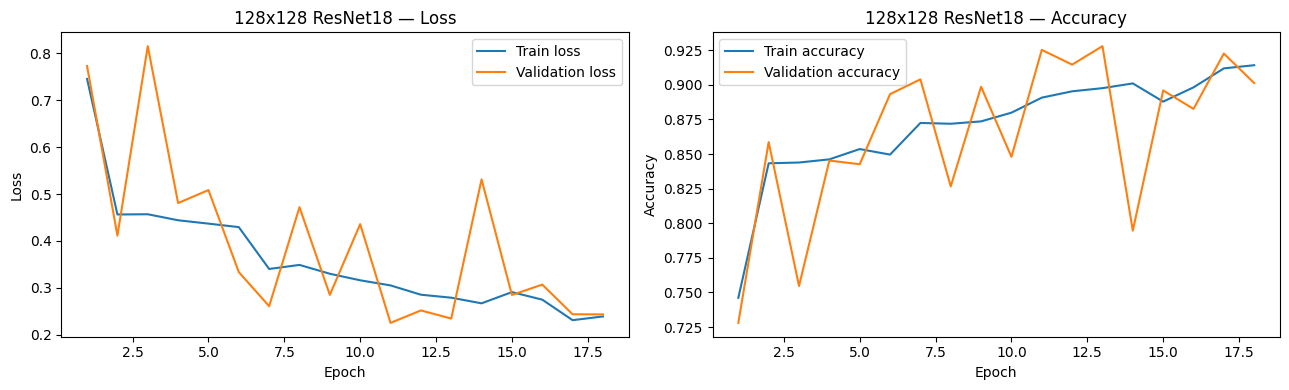

In [18]:
import matplotlib.pyplot as plt

history_df_128 = pd.DataFrame(history_128)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    history_df_128["epoch"],
    history_df_128["train_loss"],
    label="Train loss"
)
axes[0].plot(
    history_df_128["epoch"],
    history_df_128["val_loss"],
    label="Validation loss"
)
axes[0].set_title("128x128 ResNet18 — Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(
    history_df_128["epoch"],
    history_df_128["train_accuracy"],
    label="Train accuracy"
)
axes[1].plot(
    history_df_128["epoch"],
    history_df_128["val_accuracy"],
    label="Validation accuracy"
)
axes[1].set_title("128x128 ResNet18 — Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

Test Accuracy: 0.9548 (95.48%)
Checkpoint epoch: 13

Classification Report:

                        precision    recall  f1-score   support

Bare_Sparse_Vegetation     0.8977    0.9753    0.9349        81
              Built_Up     1.0000    0.9315    0.9645        73
              Cropland     0.9324    0.9200    0.9262        75
       Permanent_Water     0.9744    0.9870    0.9806        77
            Tree_Cover     0.9853    0.9571    0.9710        70

              accuracy                         0.9548       376
             macro avg     0.9580    0.9542    0.9555       376
          weighted avg     0.9565    0.9548    0.9550       376



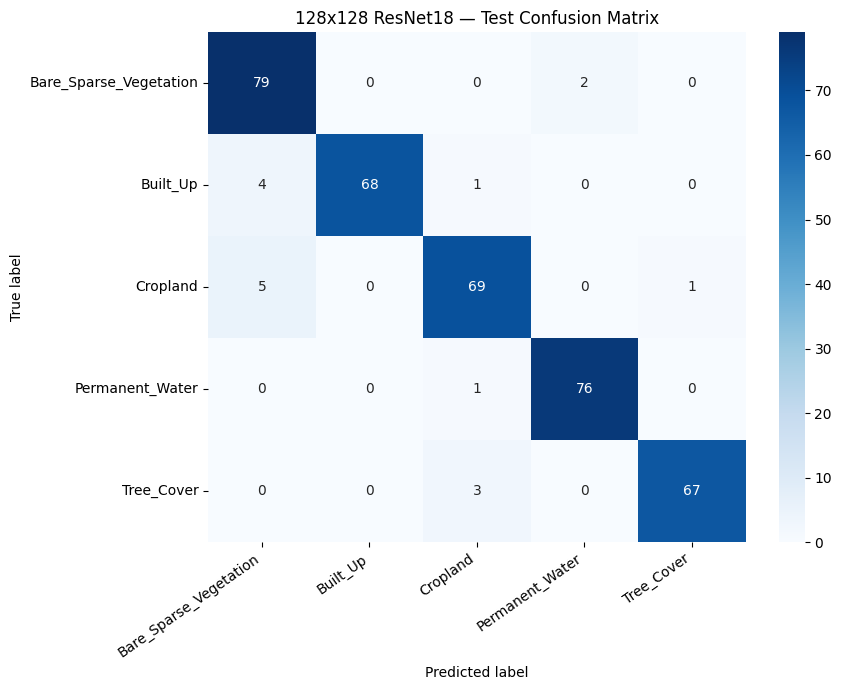

In [19]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
from torchvision import models
import torch.nn as nn

# Load the saved best checkpoint
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

model_128.load_state_dict(checkpoint["model_state_dict"])
model_128.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model_128(images)
        predictions = outputs.argmax(dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

test_accuracy = accuracy_score(all_labels, all_preds)

class_names = [
    name for name, index
    in sorted(test_loader.dataset.class_to_idx.items(),
              key=lambda item: item[1])
]

print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Checkpoint epoch: {checkpoint['epoch']}")
print("\nClassification Report:\n")
print(classification_report(
    all_labels,
    all_preds,
    target_names=class_names,
    digits=4
))

cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("128x128 ResNet18 — Test Confusion Matrix")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [20]:
from collections import Counter

print("Test images:", len(test_loader.dataset))
print("Dataset path:", test_loader.dataset.root)

print("\nClass counts:")
print(Counter(
    test_loader.dataset.classes[label]
    for _, label in test_loader.dataset.samples
))

Test images: 376
Dataset path: /content/drive/MyDrive/landcover_project/landcover_dataset_128/test

Class counts:
Counter({'Bare_Sparse_Vegetation': 81, 'Permanent_Water': 77, 'Cropland': 75, 'Built_Up': 73, 'Tree_Cover': 70})


In [22]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision import models
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import numpy as np

# 1. Correct aligned test dataset
aligned_test_dir = (
    "/content/drive/MyDrive/landcover_project/"
    "landcover_dataset_128_aligned/test"
)

eval_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_dataset_aligned = datasets.ImageFolder(
    aligned_test_dir,
    transform=eval_transform
)

test_loader_aligned = DataLoader(
    test_dataset_aligned,
    batch_size=32,
    shuffle=False
)

print("Aligned test images:", len(test_dataset_aligned))
print("Class mapping:", test_dataset_aligned.class_to_idx)

# 2. Verify expected split
from collections import Counter

class_counts = Counter(
    test_dataset_aligned.classes[label]
    for _, label in test_dataset_aligned.samples
)
print("Class counts:", class_counts)

assert len(test_dataset_aligned) == 367, (
    "Expected 367 aligned test images. Check the dataset path."
)

# 3. Recreate the model and load the saved checkpoint
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_128 = models.resnet18(weights=None)
model_128.fc = nn.Linear(model_128.fc.in_features, 5)

checkpoint_path = (
    "/content/drive/MyDrive/landcover_project/"
    "resnet18_128_aligned_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

# Support either a raw state_dict or a checkpoint dictionary
if "model_state_dict" in checkpoint:
    model_128.load_state_dict(checkpoint["model_state_dict"])
elif "state_dict" in checkpoint:
    model_128.load_state_dict(checkpoint["state_dict"])
else:
    model_128.load_state_dict(checkpoint)

model_128 = model_128.to(device)
model_128.eval()

# 4. Evaluate on the aligned test set
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader_aligned:
        images = images.to(device)

        outputs = model_128(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        all_preds.extend(predictions)
        all_labels.extend(labels.numpy())

test_accuracy = accuracy_score(all_labels, all_preds)

print(f"\nAligned Test Accuracy: {test_accuracy:.4%}")
print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(len(test_dataset_aligned.classes))),
    target_names=test_dataset_aligned.classes,
    digits=4,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(all_labels, all_preds))

Aligned test images: 367
Class mapping: {'Bare_Sparse_Vegetation': 0, 'Built_Up': 1, 'Cropland': 2, 'Permanent_Water': 3, 'Tree_Cover': 4}
Class counts: Counter({'Permanent_Water': 80, 'Bare_Sparse_Vegetation': 78, 'Tree_Cover': 71, 'Cropland': 70, 'Built_Up': 68})

Aligned Test Accuracy: 95.0954%

Classification Report:
                        precision    recall  f1-score   support

Bare_Sparse_Vegetation     0.8941    0.9744    0.9325        78
              Built_Up     1.0000    0.9559    0.9774        68
              Cropland     0.9412    0.9143    0.9275        70
       Permanent_Water     0.9737    0.9250    0.9487        80
            Tree_Cover     0.9589    0.9859    0.9722        71

              accuracy                         0.9510       367
             macro avg     0.9536    0.9511    0.9517       367
          weighted avg     0.9526    0.9510    0.9511       367

Confusion Matrix:
[[76  0  1  1  0]
 [ 3 65  0  0  0]
 [ 5  0 64  1  0]
 [ 1  0  2 74  3]
 [ 0  0 

#**Transfer Learning using pretrained weight**

In this step I am going to be using pretrained weights from the pytorch framework

In [23]:
import os
import copy
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

DRIVE_ROOT = "/content/drive/MyDrive/landcover_project"
DATASET_DIR = os.path.join(
    DRIVE_ROOT, "landcover_dataset_128_aligned"
)

assert os.path.isdir(DATASET_DIR), (
    f"Dataset folder not found: {DATASET_DIR}"
)

print("Dataset:", DATASET_DIR)

Device: cuda
GPU: Tesla T4
Dataset: /content/drive/MyDrive/landcover_project/landcover_dataset_128_aligned


In [24]:
IMG_SIZE = 128
BATCH_SIZE = 32

mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_dataset = datasets.ImageFolder(
    os.path.join(DATASET_DIR, "train"),
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    os.path.join(DATASET_DIR, "val"),
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    os.path.join(DATASET_DIR, "test"),
    transform=eval_transform
)

class_names = train_dataset.classes

assert train_dataset.class_to_idx == val_dataset.class_to_idx
assert train_dataset.class_to_idx == test_dataset.class_to_idx

loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
    generator=loader_generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

test_loader_aligned = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

print("Classes:", class_names)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))
print("Class mapping:", train_dataset.class_to_idx)

assert len(train_dataset) == 1766
assert len(val_dataset) == 367
assert len(test_dataset) == 367

Classes: ['Bare_Sparse_Vegetation', 'Built_Up', 'Cropland', 'Permanent_Water', 'Tree_Cover']
Training images: 1766
Validation images: 367
Test images: 367
Class mapping: {'Bare_Sparse_Vegetation': 0, 'Built_Up': 1, 'Cropland': 2, 'Permanent_Water': 3, 'Tree_Cover': 4}


In [25]:
weights = models.ResNet18_Weights.DEFAULT

model_pretrained = models.resnet18(weights=weights)

# Replace the original 1,000-class layer with our five classes
model_pretrained.fc = nn.Linear(
    model_pretrained.fc.in_features,
    len(class_names)
)

model_pretrained = model_pretrained.to(device)

print("Pretrained ResNet18 loaded successfully.")
print("Output classes:", model_pretrained.fc.out_features)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 86.0MB/s]

Pretrained ResNet18 loaded successfully.
Output classes: 5


In [26]:
# Freeze all pretrained layers
for param in model_pretrained.parameters():
    param.requires_grad = False

# Train the new five-class output layer
for param in model_pretrained.fc.parameters():
    param.requires_grad = True

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model_pretrained.fc.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

print(
    "Trainable parameters:",
    sum(p.numel() for p in model_pretrained.parameters()
        if p.requires_grad)
)

Trainable parameters: 2565


In [27]:
MAX_EPOCHS = 15
PATIENCE = 4

best_val_acc = -1.0
best_epoch = 0
epochs_without_improvement = 0
history = []

PRETRAINED_CHECKPOINT = os.path.join(
    DRIVE_ROOT, "resnet18_128_pretrained_best.pth"
)
HISTORY_PATH = os.path.join(
    DRIVE_ROOT, "resnet18_128_pretrained_history.csv"
)

start_time = time.time()

for epoch in range(MAX_EPOCHS):
    # Training
    model_pretrained.train()

    # Keep the frozen backbone in evaluation mode
    model_pretrained.eval()
    model_pretrained.fc.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model_pretrained(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        train_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # Validation — no weight updates
    model_pretrained.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model_pretrained(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc
    })

    print(
        f"Epoch [{epoch + 1:02d}/{MAX_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch + 1
        epochs_without_improvement = 0

        torch.save(
            model_pretrained.state_dict(),
            PRETRAINED_CHECKPOINT
        )
    else:
        epochs_without_improvement += 1

    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping.")
        break

print(f"\nBest validation accuracy: {best_val_acc:.2%}")
print("Best epoch:", best_epoch)
print(f"Training time: {(time.time() - start_time) / 60:.2f} minutes")
print("Checkpoint:", PRETRAINED_CHECKPOINT)
print("History:", HISTORY_PATH)

Epoch [01/15] Train Loss: 0.7951 | Train Acc: 0.7945 | Val Loss: 0.4356 | Val Acc: 0.8937
Epoch [02/15] Train Loss: 0.2800 | Train Acc: 0.9473 | Val Loss: 0.3169 | Val Acc: 0.9183
Epoch [03/15] Train Loss: 0.1958 | Train Acc: 0.9615 | Val Loss: 0.2512 | Val Acc: 0.9237
Epoch [04/15] Train Loss: 0.1647 | Train Acc: 0.9581 | Val Loss: 0.2258 | Val Acc: 0.9292
Epoch [05/15] Train Loss: 0.1366 | Train Acc: 0.9677 | Val Loss: 0.2079 | Val Acc: 0.9319
Epoch [06/15] Train Loss: 0.1190 | Train Acc: 0.9706 | Val Loss: 0.1981 | Val Acc: 0.9264
Epoch [07/15] Train Loss: 0.1056 | Train Acc: 0.9790 | Val Loss: 0.1931 | Val Acc: 0.9264
Epoch [08/15] Train Loss: 0.0982 | Train Acc: 0.9768 | Val Loss: 0.1833 | Val Acc: 0.9455
Epoch [09/15] Train Loss: 0.0943 | Train Acc: 0.9740 | Val Loss: 0.1705 | Val Acc: 0.9537
Epoch [10/15] Train Loss: 0.0878 | Train Acc: 0.9762 | Val Loss: 0.1624 | Val Acc: 0.9537
Epoch [11/15] Train Loss: 0.0826 | Train Acc: 0.9785 | Val Loss: 0.1589 | Val Acc: 0.9510
Epoch [12/

In [28]:
model_pretrained.load_state_dict(
    torch.load(
        PRETRAINED_CHECKPOINT,
        map_location=device,
        weights_only=True
    )
)

model_pretrained.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader_aligned:
        images = images.to(device)

        outputs = model_pretrained(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        all_preds.extend(predictions)
        all_labels.extend(labels.numpy())

test_accuracy = accuracy_score(all_labels, all_preds)

print(f"Pretrained ResNet18 Test Accuracy: {test_accuracy:.4%}")
print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(all_labels, all_preds))

Pretrained ResNet18 Test Accuracy: 95.3678%

Classification Report:
                        precision    recall  f1-score   support

Bare_Sparse_Vegetation     0.9512    1.0000    0.9750        78
              Built_Up     1.0000    0.9706    0.9851        68
              Cropland     0.9143    0.9143    0.9143        70
       Permanent_Water     0.9625    0.9625    0.9625        80
            Tree_Cover     0.9420    0.9155    0.9286        71

              accuracy                         0.9537       367
             macro avg     0.9540    0.9526    0.9531       367
          weighted avg     0.9539    0.9537    0.9536       367

Confusion Matrix:
[[78  0  0  0  0]
 [ 0 66  1  0  1]
 [ 4  0 64  0  2]
 [ 0  0  2 77  1]
 [ 0  0  3  3 65]]


In [29]:
scratch_test_accuracy = 0.950954  # Your aligned 128x128 result

comparison = pd.DataFrame([
    {
        "Model": "ResNet18 from scratch",
        "Test Accuracy": scratch_test_accuracy
    },
    {
        "Model": "Pretrained ResNet18 (frozen backbone)",
        "Test Accuracy": test_accuracy
    }
])

comparison["Test Accuracy (%)"] = (
    comparison["Test Accuracy"] * 100
).round(2)

display(comparison[["Model", "Test Accuracy (%)"]])

,Model,Test Accuracy (%)
0,ResNet18 from scratch,95.10
1,Pretrained ResNet18 (frozen backbone),95.37


##fine tuning transfer learning model

In [30]:
import os
import copy
import time
import torch
import torch.nn as nn
import pandas as pd
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PRETRAINED_CHECKPOINT = os.path.join(
    DRIVE_ROOT, "resnet18_128_pretrained_best.pth"
)

model_finetuned = models.resnet18(
    weights=None
)

model_finetuned.fc = nn.Linear(
    model_finetuned.fc.in_features,
    len(class_names)
)

model_finetuned.load_state_dict(
    torch.load(
        PRETRAINED_CHECKPOINT,
        map_location=device,
        weights_only=True
    )
)

model_finetuned = model_finetuned.to(device)

print("Loaded best frozen-backbone checkpoint.")
print("Device:", device)

Loaded best frozen-backbone checkpoint.
Device: cuda


In [31]:
# Allow all model parameters to update
for param in model_finetuned.parameters():
    param.requires_grad = True

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    [
        {
            "params": [
                p for name, p in model_finetuned.named_parameters()
                if not name.startswith("fc.")
            ],
            "lr": 1e-5
        },
        {
            "params": model_finetuned.fc.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

print("Backbone LR:", optimizer.param_groups[0]["lr"])
print("Classification head LR:", optimizer.param_groups[1]["lr"])
print(
    "Trainable parameters:",
    sum(p.numel() for p in model_finetuned.parameters()
        if p.requires_grad)
)

Backbone LR: 1e-05
Classification head LR: 0.0001
Trainable parameters: 11179077


In [32]:
MAX_EPOCHS = 15
PATIENCE = 4

best_val_acc = -1.0
best_epoch = 0
epochs_without_improvement = 0
finetune_history = []

FINETUNED_CHECKPOINT = os.path.join(
    DRIVE_ROOT, "resnet18_128_finetuned_best.pth"
)

FINETUNED_HISTORY = os.path.join(
    DRIVE_ROOT, "resnet18_128_finetuned_history.csv"
)

start_time = time.time()

for epoch in range(MAX_EPOCHS):
    model_finetuned.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model_finetuned(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        train_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # Validation
    model_finetuned.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model_finetuned(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    scheduler.step(val_acc)

    current_lr_backbone = optimizer.param_groups[0]["lr"]
    current_lr_head = optimizer.param_groups[1]["lr"]

    finetune_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "backbone_lr": current_lr_backbone,
        "head_lr": current_lr_head
    })

    print(
        f"Epoch [{epoch + 1:02d}/{MAX_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"LR: {current_lr_backbone:.1e}/"
        f"{current_lr_head:.1e}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch + 1
        epochs_without_improvement = 0

        torch.save(
            model_finetuned.state_dict(),
            FINETUNED_CHECKPOINT
        )
    else:
        epochs_without_improvement += 1

    pd.DataFrame(finetune_history).to_csv(
        FINETUNED_HISTORY,
        index=False
    )

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping.")
        break

print(f"\nBest validation accuracy: {best_val_acc:.2%}")
print("Best epoch:", best_epoch)
print(f"Training time: {(time.time() - start_time) / 60:.2f} minutes")
print("Checkpoint:", FINETUNED_CHECKPOINT)

Epoch [01/15] Train Loss: 0.5684 | Train Acc: 0.8352 | Val Loss: 0.3619 | Val Acc: 0.8910 | LR: 1.0e-05/1.0e-04
Epoch [02/15] Train Loss: 0.1932 | Train Acc: 0.9405 | Val Loss: 0.2743 | Val Acc: 0.9074 | LR: 1.0e-05/1.0e-04
Epoch [03/15] Train Loss: 0.1221 | Train Acc: 0.9643 | Val Loss: 0.2439 | Val Acc: 0.9237 | LR: 1.0e-05/1.0e-04
Epoch [04/15] Train Loss: 0.0883 | Train Acc: 0.9723 | Val Loss: 0.2093 | Val Acc: 0.9428 | LR: 1.0e-05/1.0e-04
Epoch [05/15] Train Loss: 0.0780 | Train Acc: 0.9762 | Val Loss: 0.2006 | Val Acc: 0.9428 | LR: 1.0e-05/1.0e-04
Epoch [06/15] Train Loss: 0.0789 | Train Acc: 0.9751 | Val Loss: 0.1959 | Val Acc: 0.9401 | LR: 1.0e-05/1.0e-04
Epoch [07/15] Train Loss: 0.0583 | Train Acc: 0.9841 | Val Loss: 0.1677 | Val Acc: 0.9482 | LR: 1.0e-05/1.0e-04
Epoch [08/15] Train Loss: 0.0504 | Train Acc: 0.9819 | Val Loss: 0.1688 | Val Acc: 0.9482 | LR: 1.0e-05/1.0e-04
Epoch [09/15] Train Loss: 0.0515 | Train Acc: 0.9858 | Val Loss: 0.1647 | Val Acc: 0.9537 | LR: 1.0e-05/

In [33]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

model_finetuned.load_state_dict(
    torch.load(
        FINETUNED_CHECKPOINT,
        map_location=device,
        weights_only=True
    )
)

model_finetuned.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader_aligned:
        images = images.to(device)

        outputs = model_finetuned(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        all_preds.extend(predictions)
        all_labels.extend(labels.numpy())

finetuned_accuracy = accuracy_score(all_labels, all_preds)

print(f"Fine-tuned Test Accuracy: {finetuned_accuracy:.4%}")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(all_labels, all_preds))

Fine-tuned Test Accuracy: 97.0027%

Classification Report:
                        precision    recall  f1-score   support

Bare_Sparse_Vegetation     0.9750    1.0000    0.9873        78
              Built_Up     0.9855    1.0000    0.9927        68
              Cropland     0.9178    0.9571    0.9371        70
       Permanent_Water     0.9873    0.9750    0.9811        80
            Tree_Cover     0.9848    0.9155    0.9489        71

              accuracy                         0.9700       367
             macro avg     0.9701    0.9695    0.9694       367
          weighted avg     0.9706    0.9700    0.9700       367

Confusion Matrix:
[[78  0  0  0  0]
 [ 0 68  0  0  0]
 [ 1  0 67  1  1]
 [ 1  0  1 78  0]
 [ 0  1  5  0 65]]


In [34]:
comparison = pd.DataFrame([
    {
        "Model": "ResNet18 from scratch",
        "Test Accuracy (%)": 95.10
    },
    {
        "Model": "Pretrained ResNet18 (frozen)",
        "Test Accuracy (%)": 95.37
    },
    {
        "Model": "Pretrained ResNet18 (fine-tuned)",
        "Test Accuracy (%)": round(finetuned_accuracy * 100, 2)
    }
])

display(comparison)

,Model,Test Accuracy (%)
0,ResNet18 from scratch,95.10
1,Pretrained ResNet18 (frozen),95.37
2,Pretrained ResNet18 (fine-tuned),97.00


#Visual test of the best model

In [35]:
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt
import os
import random

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class_names = [
    "Bare_Sparse_Vegetation",
    "Built_Up",
    "Cropland",
    "Permanent_Water",
    "Tree_Cover"
]

model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 5)

checkpoint_path = (
    "/content/drive/MyDrive/landcover_project/"
    "resnet18_128_finetuned_best.pth"
)

model.load_state_dict(
    torch.load(checkpoint_path, map_location=device, weights_only=True)
)
model = model.to(device)
model.eval()

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Model loaded successfully!")
print("Device:", device)

Model loaded successfully!
Device: cuda


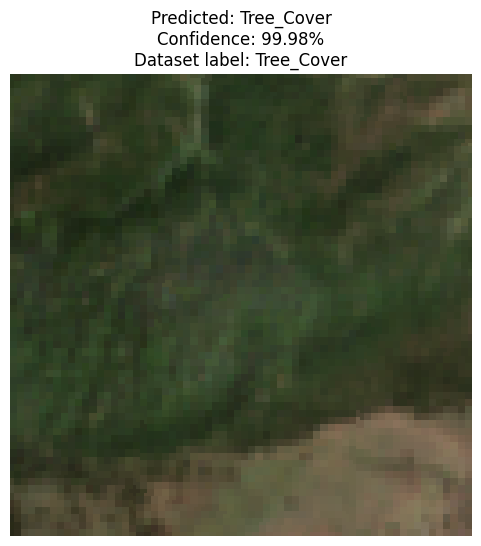

Prediction: Tree_Cover
Confidence: 99.98%
Dataset label: Tree_Cover
Correct prediction: True


In [36]:
from pathlib import Path

test_dir = Path(
    "/content/drive/MyDrive/landcover_project/"
    "landcover_dataset_128_aligned/test"
)

image_paths = [
    p for p in test_dir.rglob("*")
    if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
]

image_path = random.choice(image_paths)
true_label = image_path.parent.name

image = Image.open(image_path).convert("RGB")
input_tensor = transform(image).unsqueeze(0).to(device)

with torch.no_grad():
    logits = model(input_tensor)
    probabilities = torch.softmax(logits, dim=1)[0]

predicted_index = probabilities.argmax().item()
predicted_label = class_names[predicted_index]
confidence = probabilities[predicted_index].item() * 100

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title(
    f"Predicted: {predicted_label}\n"
    f"Confidence: {confidence:.2f}%\n"
    f"Dataset label: {true_label}"
)
plt.show()

print("Prediction:", predicted_label)
print(f"Confidence: {confidence:.2f}%")
print("Dataset label:", true_label)
print("Correct prediction:", predicted_label == true_label)

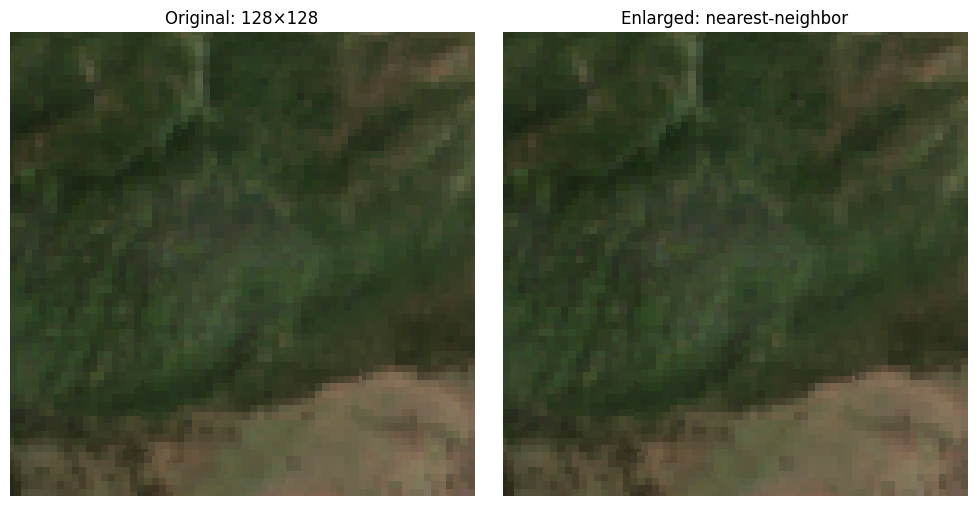

Image dimensions: (128, 128)


In [37]:
import matplotlib.pyplot as plt
from PIL import Image

image = Image.open(image_path).convert("RGB")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(image)
axes[0].set_title("Original: 128×128")
axes[0].axis("off")

axes[1].imshow(image, interpolation="nearest")
axes[1].set_title("Enlarged: nearest-neighbor")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Image dimensions:", image.size)

The sample is classified as Tree Cover, with 83.8% reference-label purity. Its location in the mountainous Tirah region is consistent with forested highland terrain. Elevation samples across the surrounding area vary by 357 m, indicating substantial local relief. However, the RGB image does not directly encode elevation, and this terrain information was not provided to the classifier

Google earth view for the tested image: https://earth.google.com/web/@33.763065,70.739110,2300a,3000d,35y,0h,0t,0r?utm_source=chatgpt.com

I have been able to assess that model is perfoming well.

In [44]:
import pandas as pd
from pathlib import Path

base = Path("/content/drive/MyDrive/landcover_project")

metadata_files = [
    base / "landcover_split_metadata.csv",
    base / "landcover_split_metadata_128.csv",
    base / "landcover_split_metadata_128_aligned.csv",
]

for path in metadata_files:
    if path.exists():
        df = pd.read_csv(path)
        print(f"\nFile: {path.name}")
        print("Columns:", df.columns.tolist())

        if "image_id" in df.columns:
            match = df[
                df["image_id"].astype(str).str.contains(
                    "01968", regex=False, na=False
                )
            ]

            if not match.empty:
                display(match)


File: landcover_split_metadata.csv
Columns: ['class_id', 'Class', 'Latitude', 'Longitude', 'Purity (%)', 'sampling_region', 'x_km', 'y_km', 'geo_group', 'split', 'image_id']


,class_id,Class,Latitude,Longitude,Purity (%),sampling_region,x_km,y_km,geo_group,split,image_id
1968,10,Tree_Cover,33.763065,70.73911,83.8,NaN,6839.860163,3758.504419,4,test,img_01968



File: landcover_split_metadata_128.csv
Columns: ['class_id', 'Class', 'Latitude', 'Longitude', 'Purity (%)', 'sampling_region', 'x_km', 'y_km', 'geo_group', 'split']

File: landcover_split_metadata_128_aligned.csv
Columns: ['class_id', 'Class', 'Latitude', 'Longitude', 'Purity (%)', 'sampling_region', 'x_km', 'y_km', 'geo_group', 'split']


Minimum elevation: 2047.0 m
Maximum elevation: 2404.0 m
Elevation range:   357.0 m


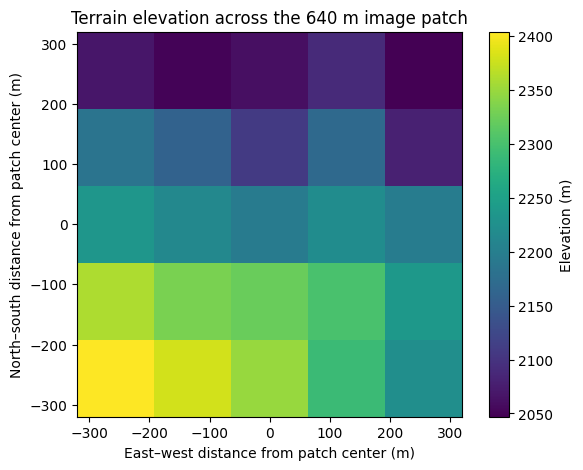

In [41]:
import requests
import numpy as np
import matplotlib.pyplot as plt

lat0 = 33.763065
lon0 = 70.739110

# Sample a 640 m × 640 m area around the image center.
# Approximately 0.00576° latitude and 0.0069° longitude
# span 640 m at this location.
latitudes = np.linspace(lat0 - 0.00288, lat0 + 0.00288, 5)
longitudes = np.linspace(lon0 - 0.00345, lon0 + 0.00345, 5)

grid_lat = np.repeat(latitudes, 5)
grid_lon = np.tile(longitudes, 5)

response = requests.get(
    "https://api.open-meteo.com/v1/elevation",
    params={
        "latitude": ",".join(map(str, grid_lat)),
        "longitude": ",".join(map(str, grid_lon))
    },
    timeout=30
)
response.raise_for_status()

elevations = np.array(response.json()["elevation"]).reshape(5, 5)

print(f"Minimum elevation: {elevations.min():.1f} m")
print(f"Maximum elevation: {elevations.max():.1f} m")
print(f"Elevation range:   {np.ptp(elevations):.1f} m")

plt.figure(figsize=(7, 5))
plt.imshow(
    elevations,
    origin="lower",
    extent=[-320, 320, -320, 320],
    aspect="equal"
)
plt.colorbar(label="Elevation (m)")
plt.xlabel("East–west distance from patch center (m)")
plt.ylabel("North–south distance from patch center (m)")
plt.title("Terrain elevation across the 640 m image patch")
plt.show()

Elevation grid (metres):
[[2404 2379 2349 2291 2224]
 [2360 2332 2323 2301 2238]
 [2235 2213 2195 2221 2197]
 [2184 2159 2108 2169 2080]
 [2068 2050 2062 2089 2047]]


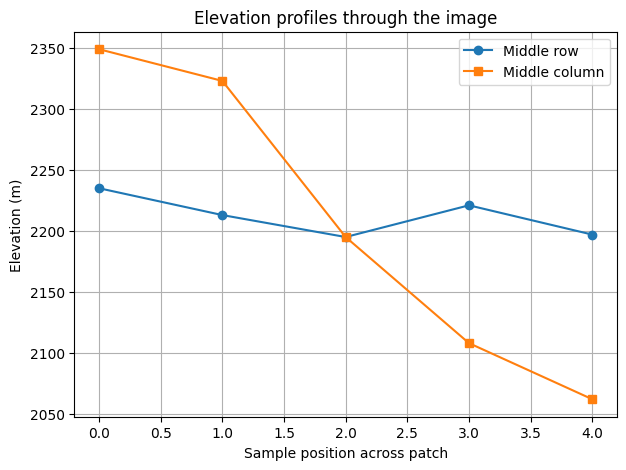

In [42]:
print("Elevation grid (metres):")
print(np.round(elevations, 0).astype(int))

plt.figure(figsize=(7, 5))
plt.plot(np.arange(5), elevations[2, :], marker="o", label="Middle row")
plt.plot(np.arange(5), elevations[:, 2], marker="s", label="Middle column")
plt.xlabel("Sample position across patch")
plt.ylabel("Elevation (m)")
plt.title("Elevation profiles through the image")
plt.legend()
plt.grid(True)
plt.show()

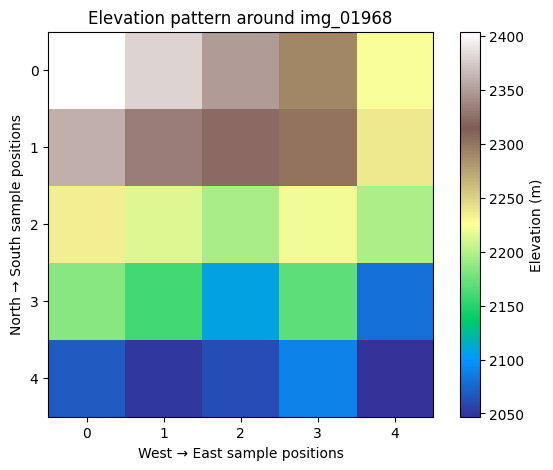

In [43]:
plt.figure(figsize=(7, 5))

plt.imshow(
    elevations,
    cmap="terrain",
    origin="upper",
    interpolation="nearest"
)

plt.colorbar(label="Elevation (m)")
plt.title("Elevation pattern around img_01968")
plt.xlabel("West → East sample positions")
plt.ylabel("North → South sample positions")
plt.xticks(range(5))
plt.yticks(range(5))
plt.show()

# Visual Test 2 with 15 images

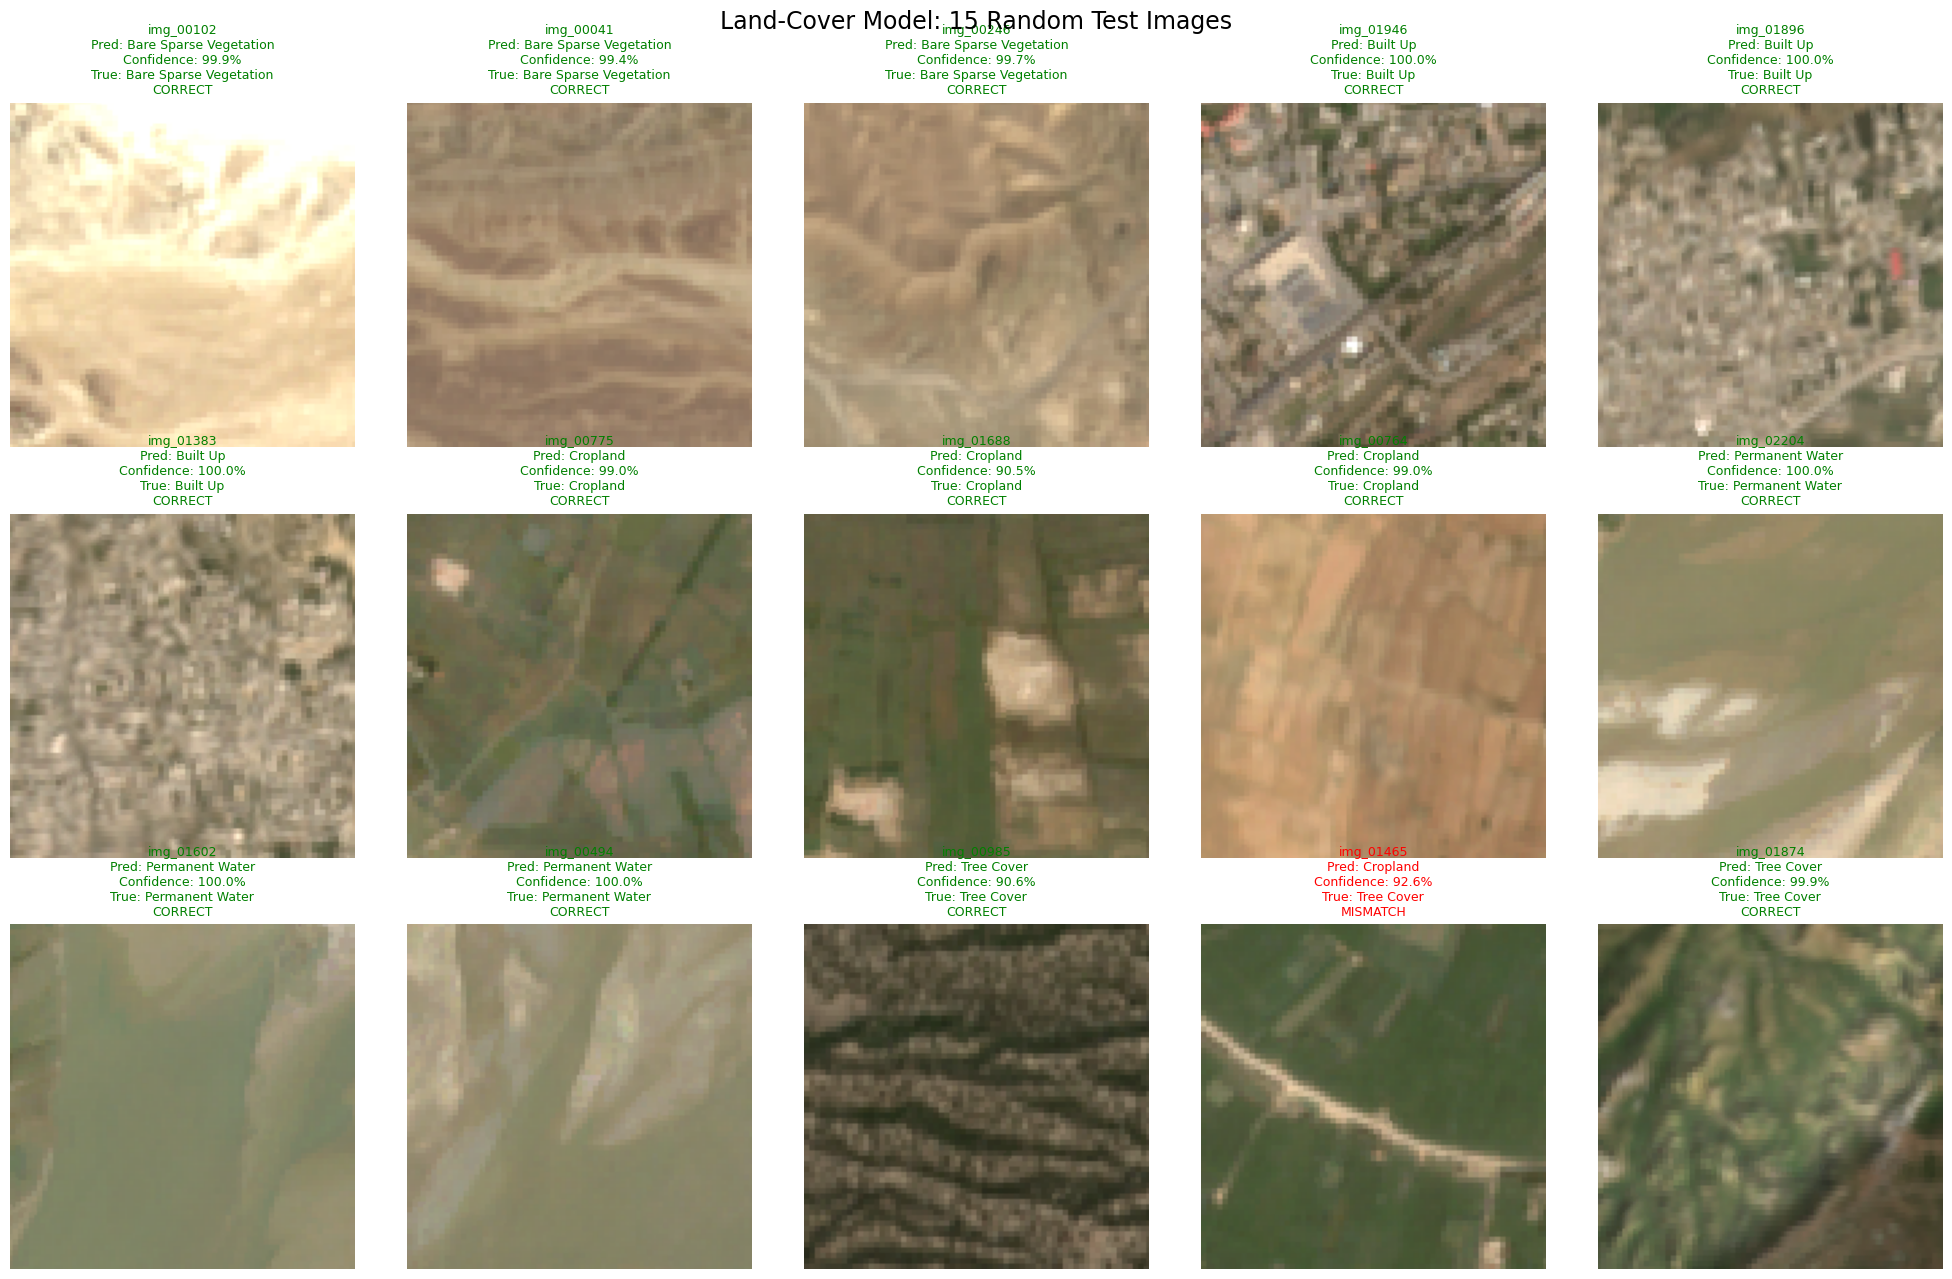

Visual inspection results:


,Image,Reference class,Predicted class,Confidence (%),Correct,Latitude,Longitude
0,img_00102.png,Bare_Sparse_Vegetation,Bare_Sparse_Vegetation,99.87,True,25.406936,61.989519
1,img_00041.png,Bare_Sparse_Vegetation,Bare_Sparse_Vegetation,99.38,True,26.205539,63.743030
2,img_00246.png,Bare_Sparse_Vegetation,Bare_Sparse_Vegetation,99.70,True,31.868518,69.319771
3,img_01946.png,Built_Up,Built_Up,99.96,True,34.001119,71.546695
4,img_01896.png,Built_Up,Built_Up,99.98,True,34.229291,72.161143
5,img_01383.png,Built_Up,Built_Up,100.00,True,34.002017,72.034480
6,img_00775.png,Cropland,Cropland,99.02,True,27.359874,68.135792
7,img_01688.png,Cropland,Cropland,90.53,True,32.067046,70.890925
8,img_00764.png,Cropland,Cropland,98.96,True,32.694968,71.817986
9,img_02204.png,Permanent_Water,Permanent_Water,99.99,True,27.314958,68.151063



Google Earth links — click to inspect each location:

img_00102.png | Bare_Sparse_Vegetation | Predicted: Bare_Sparse_Vegetation | Confidence: 99.87%
Coordinates: 25.406936435662143, 61.9895187090429
https://earth.google.com/web/@25.406936435662143,61.9895187090429,2300a,2500d,35y,0h,0t,0r
------------------------------------------------------------------------------------------
img_00041.png | Bare_Sparse_Vegetation | Predicted: Bare_Sparse_Vegetation | Confidence: 99.38%
Coordinates: 26.2055387232444, 63.743030143644205
https://earth.google.com/web/@26.2055387232444,63.743030143644205,2300a,2500d,35y,0h,0t,0r
------------------------------------------------------------------------------------------
img_00246.png | Bare_Sparse_Vegetation | Predicted: Bare_Sparse_Vegetation | Confidence: 99.7%
Coordinates: 31.868518274333866, 69.31977142745819
https://earth.google.com/web/@31.868518274333866,69.31977142745819,2300a,2500d,35y,0h,0t,0r
---------------------------------------------------

In [45]:

import os
import random
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from torchvision import models, transforms
from IPython.display import display, HTML

# ==========================================
# 1. CONFIGURATION
# ==========================================

BASE = Path("/content/drive/MyDrive/landcover_project")

TEST_DIR = BASE / "landcover_dataset_128_aligned" / "test"
METADATA_PATH = BASE / "landcover_split_metadata.csv"
CHECKPOINT_PATH = BASE / "resnet18_128_finetuned_best.pth"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class_names = [
    "Bare_Sparse_Vegetation",
    "Built_Up",
    "Cropland",
    "Permanent_Water",
    "Tree_Cover"
]

# ==========================================
# 2. LOAD MODEL
# ==========================================

model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, len(class_names))

model.load_state_dict(
    torch.load(
        CHECKPOINT_PATH,
        map_location=device,
        weights_only=True
    )
)

model.to(device)
model.eval()

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ==========================================
# 3. LOAD COORDINATE METADATA
# ==========================================

metadata = pd.read_csv(METADATA_PATH)
metadata["image_id"] = metadata["image_id"].astype(str)

metadata_lookup = metadata.set_index("image_id").to_dict("index")

# ==========================================
# 4. SELECT 3 RANDOM TEST IMAGES PER CLASS
# ==========================================

random.seed(42)
selected_images = []

for class_name in class_names:
    class_dir = TEST_DIR / class_name

    image_files = [
        p for p in class_dir.iterdir()
        if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
    ]

    # Only use images with matching coordinate metadata
    image_files = [
        p for p in image_files
        if p.stem in metadata_lookup
    ]

    if len(image_files) < 3:
        raise ValueError(
            f"Found only {len(image_files)} usable images "
            f"for {class_name}"
        )

    selected_images.extend(
        random.sample(image_files, 3)
    )

# ==========================================
# 5. RUN INFERENCE AND DISPLAY GALLERY
# ==========================================

results = []

fig, axes = plt.subplots(3, 5, figsize=(20, 13))
axes = axes.flatten()

for i, image_path in enumerate(selected_images):
    image = Image.open(image_path).convert("RGB")
    input_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(input_tensor)
        probs = torch.softmax(logits, dim=1)[0]

    pred_idx = probs.argmax().item()
    predicted_class = class_names[pred_idx]
    confidence = probs[pred_idx].item() * 100

    true_class = image_path.parent.name
    correct = predicted_class == true_class

    row = metadata_lookup[image_path.stem]
    latitude = float(row["Latitude"])
    longitude = float(row["Longitude"])

    earth_url = (
        "https://earth.google.com/web/"
        f"@{latitude},{longitude},2300a,2500d,35y,0h,0t,0r"
    )

    axes[i].imshow(image)
    axes[i].axis("off")
    axes[i].set_title(
        f"{image_path.stem}\n"
        f"Pred: {predicted_class.replace('_', ' ')}\n"
        f"Confidence: {confidence:.1f}%\n"
        f"True: {true_class.replace('_', ' ')}\n"
        f"{'CORRECT' if correct else 'MISMATCH'}",
        fontsize=9,
        color="green" if correct else "red"
    )

    results.append({
        "Image": image_path.name,
        "Reference class": true_class,
        "Predicted class": predicted_class,
        "Confidence (%)": round(confidence, 2),
        "Correct": correct,
        "Latitude": latitude,
        "Longitude": longitude,
        "Google Earth URL": earth_url
    })

plt.suptitle(
    "Land-Cover Model: 15 Random Test Images",
    fontsize=17
)
plt.tight_layout()
plt.show()

# ==========================================
# 6. PRINT COORDINATES AND GOOGLE EARTH LINKS
# ==========================================

results_df = pd.DataFrame(results)

print("Visual inspection results:")
display(results_df.drop(columns=["Google Earth URL"]))

print("\nGoogle Earth links — click to inspect each location:\n")

for _, row in results_df.iterrows():
    print(
        f"{row['Image']} | {row['Reference class']} | "
        f"Predicted: {row['Predicted class']} | "
        f"Confidence: {row['Confidence (%)']}%"
    )
    print(
        f"Coordinates: {row['Latitude']}, {row['Longitude']}"
    )
    print(row["Google Earth URL"])
    print("-" * 90)

# Save the inspection results for later
output_csv = BASE / "visual_inspection_15_images.csv"
results_df.to_csv(output_csv, index=False)

print(f"\nResults saved to: {output_csv}")
print(f"Images inspected: {len(results_df)}")
print(f"Correct predictions: {results_df['Correct'].sum()}/15")


In [46]:
import pandas as pd

metadata_path = (
    "/content/drive/MyDrive/landcover_project/"
    "landcover_split_metadata.csv"
)

df = pd.read_csv(metadata_path)

display(
    df[df["image_id"] == "img_01465"][
        ["image_id", "Class", "Purity (%)",
         "Latitude", "Longitude", "split"]
    ]
)

,image_id,Class,Purity (%),Latitude,Longitude,split
1465,img_01465,Tree_Cover,92.4,27.618589,68.315455,test
